In [1]:
from inference_tools_ppo import *
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy.stats import multivariate_normal

plt.rcParams['figure.dpi'] = 150

In [2]:
bridge = ConditionedBridge()

import numpy as np

def generate_random_values(N):
    """
    Generiert einen zufälligen Endpunkt (T_N) und eine zufällige Differenz (D) 
    der doppelt kumulativen Summe für eine Sequenz der Länge N.

    Parameter:
    - N: Länge der Summenreihe (int)

    Rückgabe:
    - (T_N, D): Tuple mit dem Endpunkt (T_N) und der Differenz (D)
    """
    # Berechnung der Varianzen und Kovarianz
    var_TN = (N * (N + 1) * (2 * N + 1)) / 6
    var_D = N
    cov_TN_D = (N * (N + 1)) / 2

    # Kovarianzmatrix
    cov_matrix = np.array([[var_TN, cov_TN_D],
                           [cov_TN_D, var_D]])

    # Erwartungswertvektor (immer 0, da mu = 0)
    mean = [0, 0]

    # Generiere eine Zufallsprobe aus der multivariaten Normalverteilung
    T_N, D = np.random.multivariate_normal(mean, cov_matrix)

    return T_N, D

def log_likelihood(T_N, D, N):
    """
    Berechnet die Log-Likelihood für die gegebenen Werte T_N (Endpunkt) und D (Differenz) 
    basierend auf einer multivariaten Normalverteilung.

    Parameter:
    - T_N: Der Endpunkt der doppelt kumulativen Summe
    - D: Die Differenz der letzten beiden Werte der doppelt kumulativen Summe
    - N: Die Länge der Summenreihe

    Rückgabe:
    - Log-Likelihood-Wert (float)
    """
    # Berechne Varianzen und Kovarianzen
    var_TN = (N * (N + 1) * (2 * N + 1)) / 6
    var_D = N
    cov_TN_D = (N * (N + 1)) / 2

    # Kovarianzmatrix
    cov_matrix = np.array([[var_TN, cov_TN_D],
                           [cov_TN_D, var_D]])

    # Berechne die Determinante und die Inverse der Kovarianzmatrix
    det_cov = np.linalg.det(cov_matrix)
    inv_cov = np.linalg.inv(cov_matrix)

    # Erstelle den Vektor der Beobachtungen
    x = np.array([T_N, D])

    # Berechne den Log-Likelihood-Wert
    d = len(x)  # Dimension der Zufallsvariablen (hier 2)
    log_likelihood_value = -0.5 * (np.log(det_cov) + x.T @ inv_cov @ x + d * np.log(2 * np.pi))

    return log_likelihood_value


def add_contours_to_existing_plot(T_N_samples, D_samples, N):
    """
    Fügt die Konturlinien der theoretischen multivariaten Normalverteilung
    zu einer bereits vorhandenen Grafik (gcf) hinzu.

    Parameter:
    - T_N_samples: Array mit den T_N-Werten (Endpunkte)
    - D_samples: Array mit den D-Werten (Differenzen)
    - N: Länge der Summenreihe (für die Berechnung der Kovarianzmatrix)
    """
    # Berechne Varianzen und Kovarianzen
    var_TN = (N * (N + 1) * (2 * N + 1)) / 6
    var_D = N
    cov_TN_D = (N * (N + 1)) / 2

    # Kovarianzmatrix
    cov_matrix = np.array([[var_TN, cov_TN_D],
                           [cov_TN_D, var_D]])

    # Erstelle ein Gitter von Punkten für die Konturen
    x = np.linspace(min(T_N_samples), max(T_N_samples), 500)
    y = np.linspace(min(D_samples), max(D_samples), 500)
    X, Y = np.meshgrid(x, y)

    # Berechne die Wahrscheinlichkeitsdichte für jedes Punkt im Gitter
    pos = np.dstack((X, Y))
    pdf = np.zeros(X.shape)

    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            pdf[i, j] = multivariate_normal.pdf([X[i, j], Y[i, j]], mean=[0, 0], cov=cov_matrix)

    # Greife auf die aktuelle Achse (gca) zu
    ax = plt.gca()

    # Zeichne die Konturlinien der theoretischen Verteilung
    contour = ax.contour(X, Y, pdf, levels=5, cmap=cm.viridis)
    ax.clabel(contour, inline=True, fontsize=8)

    #plt.draw()  # Aktualisiere die Figure, um die neuen Konturen darzustellen



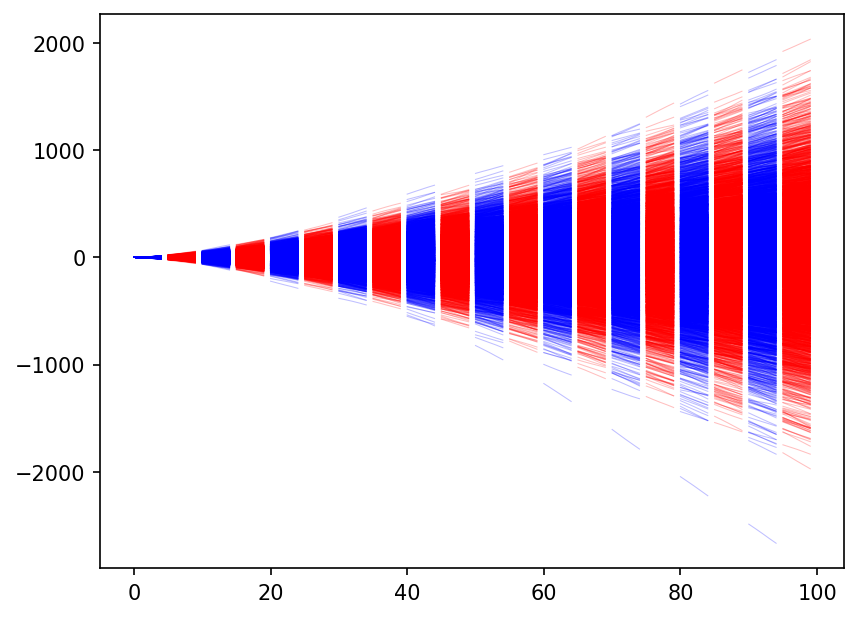

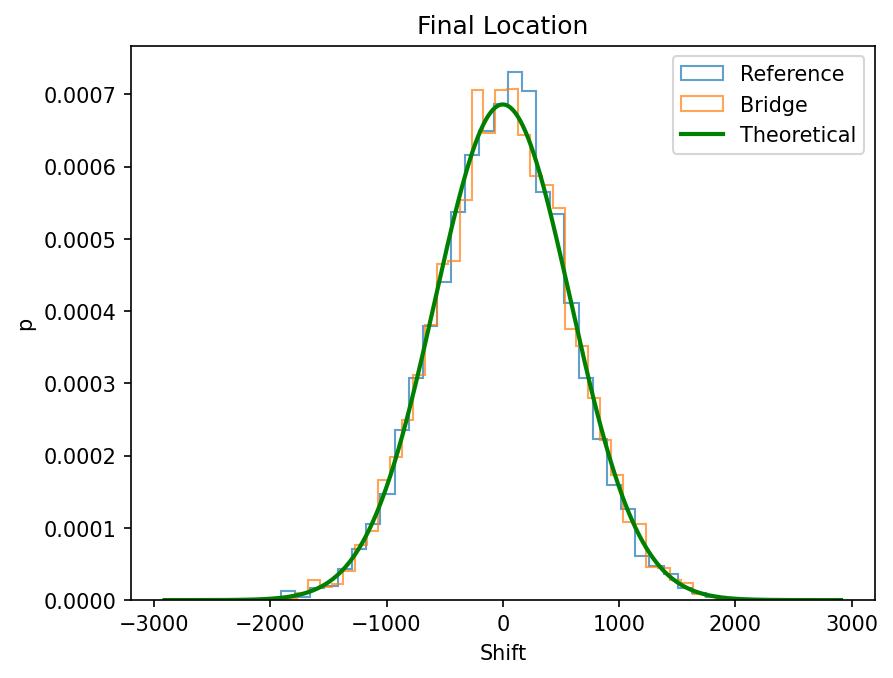

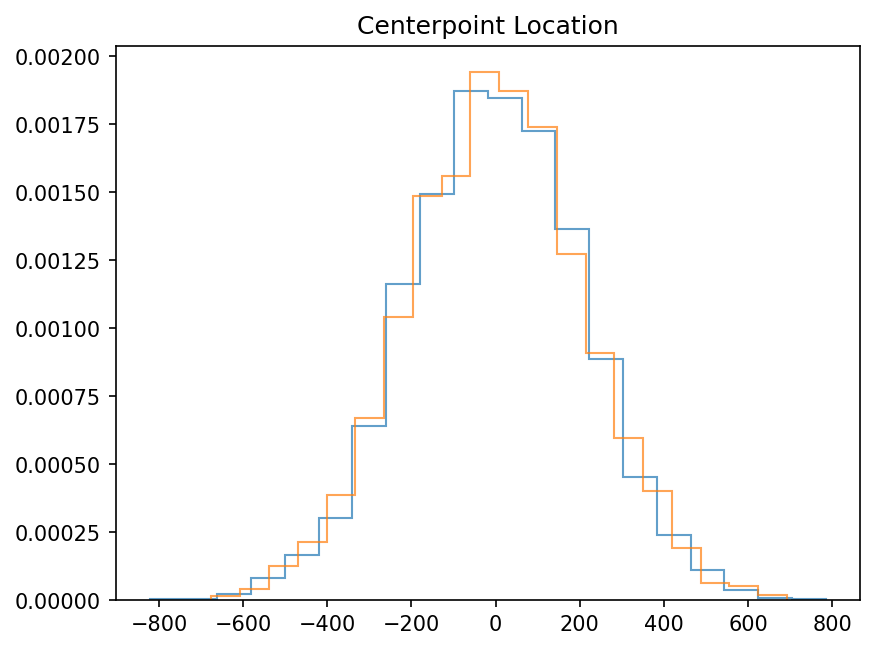

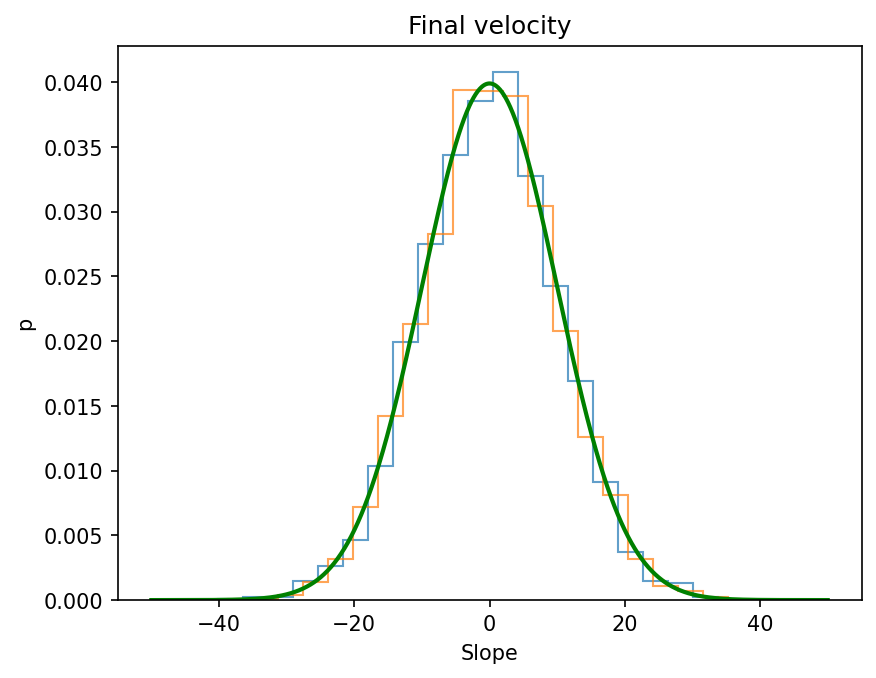

Text(0, 0.5, 'Slope')

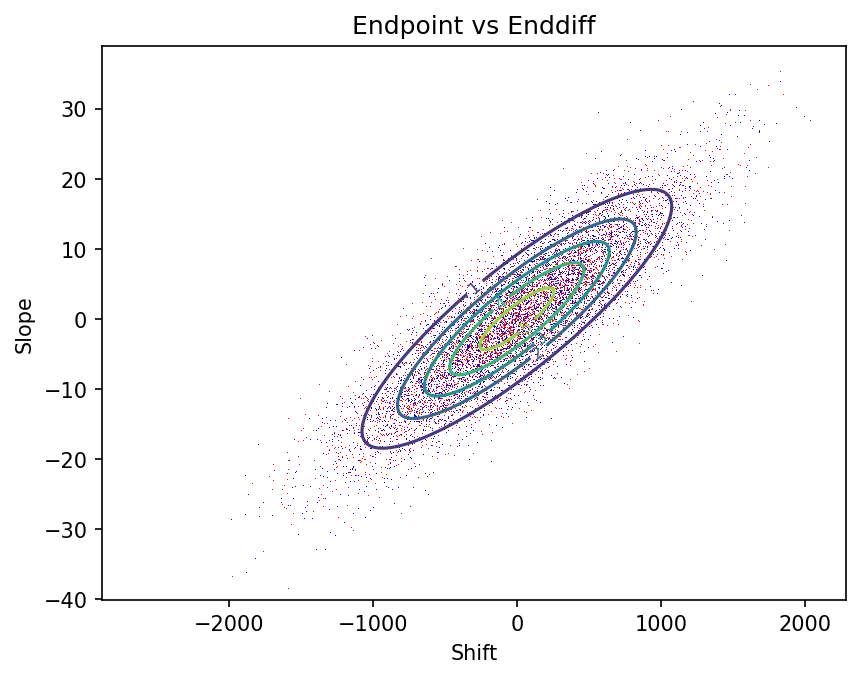

In [9]:
RNG = crng(123)
L = 100
RNG.reroll()
shift = np.array([0.])
slope = np.array([0.])
res = bridge.get(L, shift, slope, "test", 0, RNG)
std1 = res['std1']
std2 = res['std2']

N = 5000
W = []
for n in range(N):

    shift, slope = generate_random_values(L)
    shift = np.array([shift])
    slope = np.array([slope])
    #shift = np.array([1]) * np.random.randn() * np.sqrt((L+1)*L*(2*L+1) / 6)
    #slope = 0 * np.array([1])
    RNG.reroll()
    res = bridge.get(L, shift, slope, "test", 0, RNG)
    W.append(res['w'])

ref = np.random.randn(N, L)
ref[:, :1] = 0
ref = np.cumsum(np.cumsum(ref, axis=1), axis=1)
#plt.plot(ref.T, '-b', lw=0.5, alpha=0.05)

W_arr = np.stack(W).squeeze()

alternated_ref = np.copy(ref)
alternated_W = np.copy(W_arr)

# Switch values every 5 indices
for i in range(L):
    if i % 10 < 5:
        alternated_W[:, i] = np.nan  # Set W_arr to np.nan every 5 indices
    else:
        alternated_ref[:, i] = np.nan  # Set ref to np.nan every 5 indices

# Plot the alternating lines
plt.plot(alternated_ref.T, '-b', lw=0.5, alpha=0.25, label='Ref (alternating)')
plt.plot(alternated_W.T, '-r', lw=0.5, alpha=0.25, label='W_arr (alternating)')
plt.show()

plt.hist(ref[:,-1], facecolor='b', bins=40, alpha=0.7, density=True, histtype='step', label='Reference')
plt.hist(W_arr[:,-1], facecolor='r', bins=40, alpha=0.7, density=True, histtype='step', label='Bridge')
x = np.linspace(-5 * np.sqrt((L+1)*L*(2*L+1) / 6), 5 * np.sqrt((L+1)*L*(2*L+1) / 6), 1000)
plt.plot(x, 1/(np.sqrt(2 * np.pi) * np.sqrt((L+1)*L*(2*L+1) / 6)) * np.exp(-0.5 * (x**2 / ((L+1)*L*(2*L+1) / 6))), 'g-', lw=2, label='Theoretical')
plt.title("Final Location")
plt.xlabel("Shift")
plt.ylabel("p")
plt.legend()
plt.show()

plt.hist(ref[:,L//2], facecolor='b', bins=20, alpha=0.7, density=True, histtype='step')
plt.hist(W_arr[:,L//2], facecolor='r', bins=20, alpha=0.7, density=True, histtype='step')
plt.title("Centerpoint Location")
plt.show()

plt.hist(np.diff(ref, axis=1)[:,-1], facecolor='b', bins=20, alpha=0.7, density=True, histtype='step')
plt.hist(np.diff(W_arr, axis=1)[:,-1], facecolor='r', bins=20, alpha=0.7, density=True, histtype='step')
x = np.linspace(-5 * np.sqrt(L), 5 * np.sqrt(L), 1000)
plt.plot(x, 1/(np.sqrt(2 * np.pi) * np.sqrt(L)) * np.exp(-0.5 * (x**2 / L)), 'g-', lw=2)
plt.xlabel("Slope")
plt.ylabel("p")
plt.title("Final velocity")
plt.show()

plt.title("Endpoint vs Enddiff")
plt.plot(ref[:,-1], np.diff(ref, axis=1)[:,-1], ',b')
plt.plot(W_arr[:,-1], np.diff(W_arr, axis=1)[:,-1], ',r')
add_contours_to_existing_plot(ref[:,-1], np.diff(ref, axis=1)[:,-1], L)
plt.xlabel("Shift")
plt.ylabel("Slope")

In [4]:
std2

284.3413441622586